# Clasificador de productos para inventario

Clasifica fotos de productos de supermercado en **sección** (Frutas, Verduras, Lácteos, Bebidas, Snacks y dulces, Despensa, Conservas) y **producto** (63 clases).

- Datasets públicos: [Freiburg Groceries](http://aisdatasets.informatik.uni-freiburg.de/freiburg_groceries_dataset/) (productos envasados) + [Grocery Store Dataset](https://github.com/marcusklasson/GroceryStoreDataset) (frutas, verduras y lácteos).
- Modelo: **MobileNetV2** preentrenado en ImageNet (transfer learning) + una capa de clasificación.
- Al final se exporta a **TensorFlow.js** para usarlo en la web con la cámara.

In [1]:
!pip install -q tensorflowjs tf_keras

In [2]:
import os, json, subprocess
import numpy as np
import tensorflow as tf
import tf_keras as keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

print("TensorFlow", tf.__version__, "| tf_keras", keras.__version__)

TensorFlow 2.19.0 | tf_keras 2.19.0


## 1. Descargar los datasets

In [3]:
os.makedirs('datos', exist_ok=True)

if not os.path.isdir('datos/GroceryStoreDataset'):
    subprocess.run(['git', 'clone', '-q', '--depth', '1',
                    'https://github.com/marcusklasson/GroceryStoreDataset.git',
                    'datos/GroceryStoreDataset'], check=True)

if not os.path.isdir('datos/images'):
    url = 'http://aisdatasets.informatik.uni-freiburg.de/freiburg_groceries_dataset/freiburg_groceries_dataset.tar.gz'
    subprocess.run(['curl', '-s', '-o', 'datos/freiburg.tar', url], check=True)
    subprocess.run(['tar', 'xf', 'datos/freiburg.tar', '-C', 'datos'], check=True)
    os.remove('datos/freiburg.tar')

print(sorted(os.listdir('datos')))

['GroceryStoreDataset', 'freiburg.tar.gz', 'images']


## 2. Secciones y productos

Cada carpeta de los datasets se asigna a un producto en español y a su sección del inventario.

In [4]:
CATALOGO = {
  'Frutas': {
    'Manzana': ['gs:Apple'], 'Aguacate': ['gs:Avocado'], 'Plátano': ['gs:Banana'], 'Kiwi': ['gs:Kiwi'],
    'Limón': ['gs:Lemon'], 'Lima': ['gs:Lime'], 'Mango': ['gs:Mango'], 'Melón / sandía': ['gs:Melon'],
    'Nectarina': ['gs:Nectarine'], 'Naranja': ['gs:Orange'], 'Papaya': ['gs:Papaya'],
    'Maracuyá': ['gs:Passion-Fruit'], 'Melocotón': ['gs:Peach'], 'Pera': ['gs:Pear'], 'Piña': ['gs:Pineapple'],
    'Ciruela': ['gs:Plum'], 'Granada': ['gs:Pomegranate'], 'Pomelo': ['gs:Red-Grapefruit'],
    'Mandarina': ['gs:Satsumas'],
  },
  'Verduras': {
    'Espárrago': ['gs:Asparagus'], 'Berenjena': ['gs:Aubergine'], 'Champiñón': ['gs:Brown-Cap-Mushroom', 'gs:Mushroom'],
    'Repollo': ['gs:Cabbage'], 'Zanahoria': ['gs:Carrots'], 'Pepino': ['gs:Cucumber'], 'Ajo': ['gs:Garlic'],
    'Jengibre': ['gs:Ginger'], 'Puerro': ['gs:Leek'], 'Cebolla': ['gs:Onion'], 'Pimiento': ['gs:Pepper'],
    'Patata': ['gs:Potato'], 'Remolacha': ['gs:Red-Beet'], 'Tomate': ['gs:Tomato'], 'Calabacín': ['gs:Zucchini'],
  },
  'Lácteos': {
    'Leche': ['gs:Milk', 'fr:MILK'], 'Yogur': ['gs:Yoghurt', 'gs:Soyghurt', 'gs:Oatghurt'],
    'Bebida vegetal (avena / soja)': ['gs:Oat-Milk', 'gs:Soy-Milk'], 'Nata agria': ['gs:Sour-Cream'],
    'Leche fermentada': ['gs:Sour-Milk'],
  },
  'Bebidas': {
    'Agua': ['fr:WATER'], 'Refresco': ['fr:SODA'], 'Zumo': ['gs:Juice', 'fr:JUICE'],
    'Café': ['fr:COFFEE'], 'Té': ['fr:TEA'],
  },
  'Snacks y dulces': {
    'Patatas fritas (chips)': ['fr:CHIPS'], 'Chocolate': ['fr:CHOCOLATE'], 'Caramelos': ['fr:CANDY'],
    'Pasteles / galletas': ['fr:CAKE'], 'Frutos secos': ['fr:NUTS'],
  },
  'Despensa': {
    'Pasta': ['fr:PASTA'], 'Arroz': ['fr:RICE'], 'Harina': ['fr:FLOUR'], 'Azúcar': ['fr:SUGAR'],
    'Cereales': ['fr:CEREAL'], 'Aceite': ['fr:OIL'], 'Vinagre': ['fr:VINEGAR'], 'Miel': ['fr:HONEY'],
    'Mermelada': ['fr:JAM'], 'Especias': ['fr:SPICES'],
  },
  'Conservas': {
    'Alubias': ['fr:BEANS'], 'Maíz': ['fr:CORN'], 'Pescado en lata': ['fr:FISH'],
    'Salsa de tomate': ['fr:TOMATO_SAUCE'],
  },
}

CLASES = [{'producto': p, 'seccion': s} for s, prods in CATALOGO.items() for p in prods]
ORIGEN = {o: i for i, c in enumerate(CLASES) for o in CATALOGO[c['seccion']][c['producto']]}
print(len(CLASES), 'productos en', len(CATALOGO), 'secciones')

63 productos en 7 secciones


In [5]:
rutas, etiquetas = [], []

gs = 'datos/GroceryStoreDataset/dataset'
for split in ['train.txt', 'val.txt', 'test.txt']:
    for linea in open(os.path.join(gs, split)):
        ruta = linea.split(',')[0].strip()
        if not ruta:
            continue
        carpeta = ruta.split('/')[2]  # split/Tipo/Clase/...
        rutas.append(os.path.join(gs, ruta)); etiquetas.append(ORIGEN['gs:' + carpeta])

for carpeta in sorted(os.listdir('datos/images')):
    for f in sorted(os.listdir(os.path.join('datos/images', carpeta))):
        rutas.append(os.path.join('datos/images', carpeta, f)); etiquetas.append(ORIGEN['fr:' + carpeta])

rutas, etiquetas = np.array(rutas), np.array(etiquetas)
conteo = np.bincount(etiquetas, minlength=len(CLASES))
print(len(rutas), 'imágenes | mín por producto:', conteo.min(), '| máx:', conteo.max())

r_train, r_tmp, y_train, y_tmp = train_test_split(rutas, etiquetas, test_size=0.2, stratify=etiquetas, random_state=42)
r_val, r_test, y_val, y_test = train_test_split(r_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)
print('entrenamiento', len(r_train), '| validación', len(r_val), '| prueba', len(r_test))

10368 imágenes | mín por producto: 35 | máx: 797
entrenamiento 8294 | validación 1037 | prueba 1037


## 3. Ver algunas imágenes

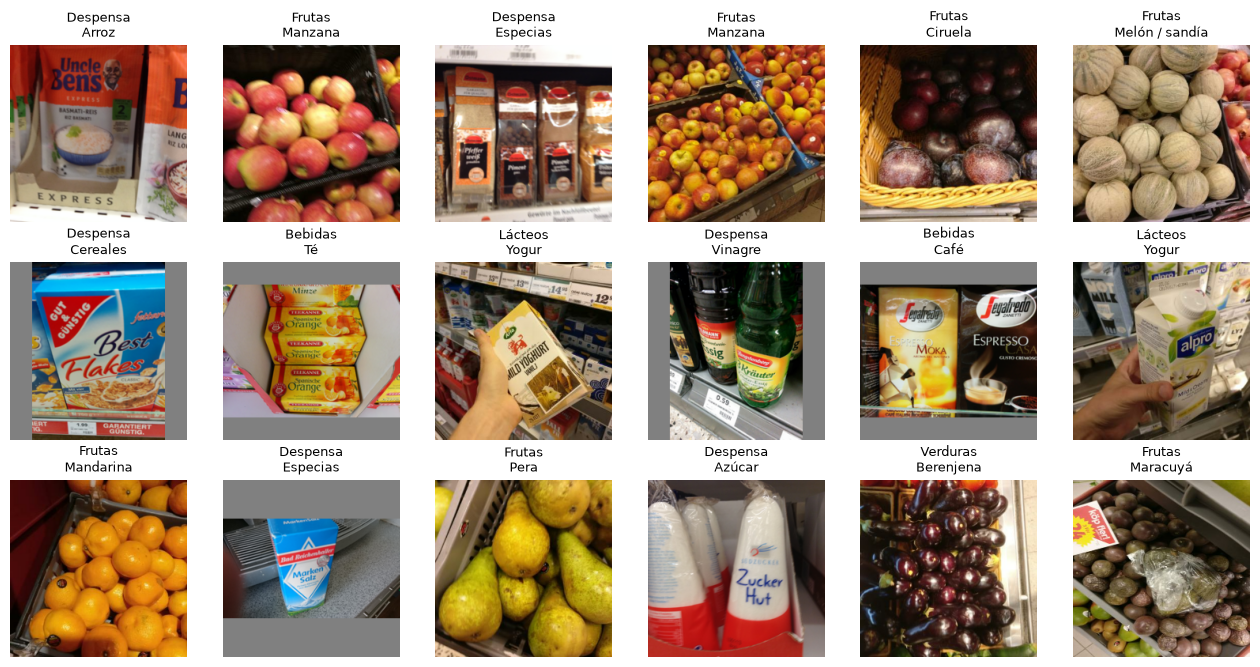

In [6]:
TAMANO_IMG = 224

def cargar(ruta):
    img = tf.io.decode_image(tf.io.read_file(ruta), channels=3, expand_animations=False)
    return tf.image.resize(img, (TAMANO_IMG, TAMANO_IMG))

plt.figure(figsize=(16, 8))
for i, j in enumerate(np.random.RandomState(0).choice(len(r_train), 18, replace=False)):
    plt.subplot(3, 6, i + 1)
    plt.imshow(cargar(r_train[j]).numpy().astype('uint8'))
    c = CLASES[y_train[j]]
    plt.title(f"{c['seccion']}\n{c['producto']}", fontsize=9); plt.axis('off')
plt.show()

## 4. Extraer características con MobileNetV2

MobileNetV2 (preentrenado) convierte cada imagen en un vector de 1280 números. Se calcula una sola vez, lo que hace el entrenamiento muy rápido incluso sin GPU.
Para el entrenamiento se añaden copias con **aumento de datos** (volteo, recorte, brillo y contraste).

In [7]:
base = keras.applications.MobileNetV2(input_shape=(TAMANO_IMG, TAMANO_IMG, 3), include_top=False,
                                      weights='imagenet', pooling='avg')
base.trainable = False

def aumentar(img):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.resize(tf.image.random_crop(img, (190, 190, 3)), (TAMANO_IMG, TAMANO_IMG))
    img = tf.image.random_brightness(img, 40)
    img = tf.image.random_contrast(img, 0.8, 1.2)
    return tf.clip_by_value(img, 0, 255)

def caracteristicas(r, aumento=False):
    ds = tf.data.Dataset.from_tensor_slices(r).map(cargar, num_parallel_calls=tf.data.AUTOTUNE)
    if aumento:
        ds = ds.map(aumentar, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda x: x / 127.5 - 1).batch(64).prefetch(tf.data.AUTOTUNE)
    return base.predict(ds, verbose=0)

tf.random.set_seed(0)
X_train = np.concatenate([caracteristicas(r_train)] + [caracteristicas(r_train, aumento=True) for _ in range(2)])
Y_train = np.concatenate([y_train] * 3)
X_val, X_test = caracteristicas(r_val), caracteristicas(r_test)
print(X_train.shape, X_val.shape, X_test.shape)

(24882, 1280) (1037, 1280) (1037, 1280)


## 5. Entrenar el clasificador

In [8]:
cabeza = keras.Sequential([
    keras.layers.Input(shape=(1280,)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(len(CLASES), activation='softmax'),
])
cabeza.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

historial = cabeza.fit(X_train, Y_train, validation_data=(X_val, y_val), epochs=40, batch_size=128,
                       callbacks=[keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)], verbose=2)

Epoch 1/40


195/195 - 1s - loss: 1.6043 - accuracy: 0.5567 - val_loss: 0.8248 - val_accuracy: 0.7695 - 664ms/epoch - 3ms/step


Epoch 2/40


195/195 - 0s - loss: 0.6955 - accuracy: 0.8010 - val_loss: 0.6301 - val_accuracy: 0.8235 - 350ms/epoch - 2ms/step


Epoch 3/40


...

195/195 - 0s - loss: 0.1658 - accuracy: 0.9520 - val_loss: 0.4623 - val_accuracy: 0.8698 - 364ms/epoch - 2ms/step


Epoch 19/40


195/195 - 0s - loss: 0.1577 - accuracy: 0.9527 - val_loss: 0.4624 - val_accuracy: 0.8631 - 351ms/epoch - 2ms/step


Epoch 20/40


195/195 - 0s - loss: 0.1568 - accuracy: 0.9547 - val_loss: 0.4767 - val_accuracy: 0.8669 - 334ms/epoch - 2ms/step


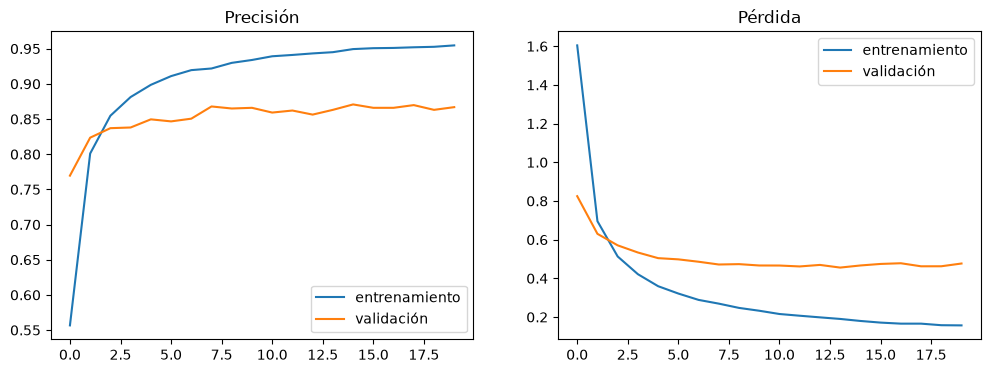

In [9]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1); plt.plot(historial.history['accuracy'], label='entrenamiento'); plt.plot(historial.history['val_accuracy'], label='validación'); plt.title('Precisión'); plt.legend()
plt.subplot(1, 2, 2); plt.plot(historial.history['loss'], label='entrenamiento'); plt.plot(historial.history['val_loss'], label='validación'); plt.title('Pérdida'); plt.legend()
plt.show()

## 6. Evaluar con imágenes que el modelo no ha visto

In [10]:
pred = cabeza.predict(X_test, verbose=0).argmax(1)
sec = np.array([c['seccion'] for c in CLASES])
print(f"Acierto en producto: {(pred == y_test).mean():.1%}")
print(f"Acierto en sección:  {(sec[pred] == sec[y_test]).mean():.1%}")

print('\nAcierto por sección:')
for s in CATALOGO:
    m = sec[y_test] == s
    print(f"  {s:16s} {(pred[m] == y_test[m]).mean():.1%}  ({m.sum()} imágenes)")

errores = {}
for a, b in zip(y_test, pred):
    if a != b:
        errores[(a, b)] = errores.get((a, b), 0) + 1
print('\nConfusiones más frecuentes:')
for (a, b), n in sorted(errores.items(), key=lambda x: -x[1])[:8]:
    print(f"  {CLASES[a]['producto']} -> {CLASES[b]['producto']}: {n}")

Acierto en producto: 85.1%
Acierto en sección:  91.6%

Acierto por sección:
  Frutas           90.7%  (237 imágenes)
  Verduras         99.2%  (130 imágenes)
  Lácteos          92.3%  (143 imágenes)
  Bebidas          81.8%  (181 imágenes)
  Snacks y dulces  72.9%  (118 imágenes)
  Despensa         72.9%  (177 imágenes)
  Conservas        86.3%  (51 imágenes)

Confusiones más frecuentes:
  Vinagre -> Aceite: 6
  Zumo -> Té: 4
  Café -> Chocolate: 4
  Pasteles / galletas -> Cereales: 4
  Naranja -> Mandarina: 3
  Mermelada -> Especias: 3
  Caramelos -> Cereales: 3
  Café -> Caramelos: 2


## 7. Modelo completo (imagen → producto) y exportación a TensorFlow.js

In [11]:
entrada = keras.layers.Input(shape=(TAMANO_IMG, TAMANO_IMG, 3))  # píxeles 0-255
x = keras.layers.Rescaling(1 / 127.5, offset=-1)(entrada)
x = base(x, training=False)
salida = cabeza(x)
modelo = keras.Model(entrada, salida)

# Comprobar que el modelo completo da lo mismo que base + cabeza
muestra = np.stack([cargar(r).numpy() for r in r_test[:32]])
print('Coinciden:', (modelo.predict(muestra, verbose=0).argmax(1) == pred[:32]).all())

modelo.save('clasificador-inventario.h5')

Coinciden: True


In [12]:
import tensorflowjs as tfjs

tfjs.converters.save_keras_model(modelo, 'carpeta_salida')
with open('carpeta_salida/clases.json', 'w', encoding='utf-8') as f:
    json.dump(CLASES, f, ensure_ascii=False, indent=1)
print(sorted(os.listdir('carpeta_salida')))

['clases.json', 'group1-shard1of3.bin', 'group1-shard2of3.bin', 'group1-shard3of3.bin', 'model.json']


## 8. Probar con imágenes de prueba

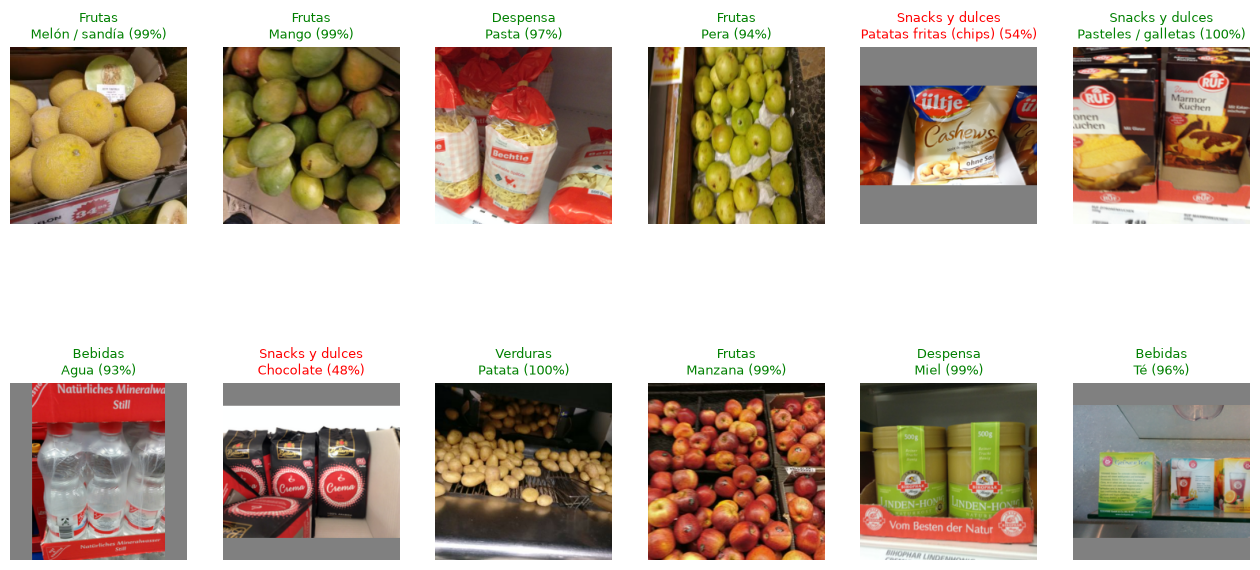

In [13]:
plt.figure(figsize=(16, 8))
idx = np.random.RandomState(1).choice(len(r_test), 12, replace=False)
probs = modelo.predict(np.stack([cargar(r_test[j]).numpy() for j in idx]), verbose=0)
for i, j in enumerate(idx):
    plt.subplot(2, 6, i + 1)
    plt.imshow(cargar(r_test[j]).numpy().astype('uint8'))
    p, real = CLASES[probs[i].argmax()], CLASES[y_test[j]]
    plt.title(f"{p['seccion']}\n{p['producto']} ({probs[i].max():.0%})", fontsize=9,
              color='green' if p == real else 'red')
    plt.axis('off')
plt.show()